## -------------------------------------------------------------------------------------------------------------------

# PROYECTO DEL CEIEC - Network Traffic Classification, en colaboración con Foqum
# Descripción del notebook: captura de tráfico y clasificación en tiempo real
# Becario responsable del proyecto: Carlos Arranz Luque
# Directora de la investigación: Ana María Maitín López
# Fecha: curso académico 2022-2023

## -------------------------------------------------------------------------------------------------------------------

In [1]:
import subprocess
import configparser
import os
import time

## Módulos/scripts propios
from src import *

## Este código recarga los módulos/librerías antes de cada ejecución parcial del código, de tal forma
## que podemos cambiar una función en mitad de la ejecución y dichos cambios serán efectivos sin necesidad
## de recargar el kernel. Esto es útil cuando aún se está en fase de desarrollo y hay que verificar si las
## funciones tienen el comportamiento deseado
%load_ext autoreload
%autoreload 2

2023-07-10 23:09:22.093713: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


## -------------------------------------------------------------------------------------------------------------------

## Opciones de ejecución e hiperparámetros

In [2]:
## Leemos el archivo "config_tiempo_real.cfg" donde están las opciones de ejecución e hiperparámetros
config = configparser.RawConfigParser()
config.read('config/config_tiempo_real.cfg')

## Optenemos los diccionarios con los distintos parámetros de cada una de las categorías
opcionesEjecucion_dict = dict(config.items('OpcionesEjecucion'))
hiperparametros_dict = dict(config.items('Hiperparametros'))
rutasArchivos_dict = dict(config.items('RutasArchivos'))

In [3]:
### ----------------------------------------------------------------------------------------------
### ------------------------------ Opciones de ejecución -----------------------------------------
### ----------------------------------------------------------------------------------------------

# tipo_modelo                -->  Indica el modelo de clasificación que será utilizado 
#                                 Actualmente existe el Transformer (XFMR) y el LSTM
# hash_pesos_modelo          -->  Indica el hash del modelo cuyos pesos queremos cargar 
# hash_pesos_semiflujos      -->  Indica el hash de los semiflujos usados para entrenar el 
#                                 modelo cuyos pesos queremos cargar. (Debe existir la combinación 
#                                 de modelo y semiflujos en el directorio de pesos correspondiente)


tipo_modelo = opcionesEjecucion_dict['tipo_modelo']

hash_pesos_modelo = opcionesEjecucion_dict['hash_pesos_modelo']

hash_pesos_semiflujos = opcionesEjecucion_dict['hash_pesos_semiflujos']



### ----------------------------------------------------------------------------------------------
### --------------------------------- Hiperparámetros --------------------------------------------
### ----------------------------------------------------------------------------------------------

# tiempo_captura_pcap --> Número de segundos de cada grabación de TShark. Iterativamente, cada x 
#                         segundos se generará un nuevo archivo PCAP, y se comenzará la grabación 
#                         del siguiente.

tiempo_captura_pcap = float(hiperparametros_dict['tiempo_captura_pcap'])


### ----------------------------------------------------------------------------------------------
### ----------------------------------- Rutas archivos -------------------------------------------
### ----------------------------------------------------------------------------------------------

# En "rutaSemiflujos" tenemos el directorio que almacena los semiflujos
# En "rutaPesosXFMR" tenemos el directorio que almacena los pesos del Transformer
# En "rutaPesosLSTM" tenemos el directorio que almacena los pesos de la LSTM

rutaCapturasTiempoRealPCAP = rutasArchivos_dict["rutacapturastiemporealpcap"]
rutaCapturasTiempoRealCSV = rutasArchivos_dict["rutacapturastiemporealcsv"]
rutaSemiflujos = rutasArchivos_dict["rutasemiflujos"]
rutaPesosXFMR = rutasArchivos_dict["rutapesosxfmr"]
rutaPesosLSTM = rutasArchivos_dict["rutapesoslstm"]
rutaConfigXFMR = rutasArchivos_dict["rutaconfigxfmr"]
rutaConfigLSTM = rutasArchivos_dict["rutaconfiglstm"]


## -------------------------------------------------------------------------------------------------------------------

## Mostramos los parámetros leídos del archivo de configuración 
### (Así nos cercioramos qué ha leído el programa y evitamos errores de configuración)

In [4]:
print("Parámetros leídos del archivo de configuración: \n")
print("Tipo de modelo = "+tipo_modelo)
print("Hash pesos modelo = "+hash_pesos_modelo)
print("Hash pesos semiflujos = "+hash_pesos_semiflujos)

print("Tiempo de captura de cada PCAP = "+str(tiempo_captura_pcap))

print("Ruta capturas tiempo real PCAP = "+rutaCapturasTiempoRealPCAP)
print("Ruta capturas tiempo real CSV = "+rutaCapturasTiempoRealCSV)
print("Ruta semiflujos = "+rutaSemiflujos)
print("Ruta pesos Transformer = "+rutaPesosXFMR)
print("Ruta pesos LSTM = "+rutaPesosLSTM)
print("Ruta configuracion Transformer = "+rutaConfigXFMR)
print("Ruta configuracion LSTM = "+rutaConfigLSTM)

Parámetros leídos del archivo de configuración: 

Tipo de modelo = XFMR
Hash pesos modelo = fe693df6778a35ca5a920dfa73b35b69
Hash pesos semiflujos = 060eaab55e1e0dd2d41fe88ed69ebb5b
Tiempo de captura de cada PCAP = 8.0
Ruta capturas tiempo real PCAP = Capturas_tiempo_real/PCAPs/
Ruta capturas tiempo real CSV = Capturas_tiempo_real/CSVs/
Ruta semiflujos = Objetos preprocesados/Semiflujos/
Ruta pesos Transformer = Objetos preprocesados/Pesos_TransformerSimple/
Ruta pesos LSTM = Objetos preprocesados/Pesos_LSTM/
Ruta configuracion Transformer = Resultados/Resultados_TransformerSimple/Archivos de configuracion/
Ruta configuracion LSTM = Resultados/Resultados_LSTM/Archivos de configuracion/


## -------------------------------------------------------------------------------------------------------------------

## Generamos el modelo indicado

In [5]:
## Llamamos a la función que nos devuelve todos los datos necesarios para reconstruir el modelo indicado

if (tipo_modelo == "LSTM"):
    print("Obteniendo parámetros del modelo LSTM...")
    num_capas_lstm,hidden_state,mlp_units,lstm_dropout,mlp_dropout,batch_size,learning_rate,normalizar,\
    n_clases,clases_clasificador,input_shape = obtener_hiperparametros_LSTM(rutaConfigLSTM,hash_pesos_modelo,hash_pesos_semiflujos,rutaSemiflujos)
elif(tipo_modelo == "XFMR"):
    print("Obteniendo parámetros del modelo XFMR...")
    batch_size,learning_rate,positional_encoding,num_heads,head_size,mlp_units,ff_dim,mlp_dropout,dropout,\
    num_capas_atencion,normalizar,n_clases,clases_clasificador,input_shape = obtener_hiperparametros_XFMR(rutaConfigXFMR,hash_pesos_modelo,hash_pesos_semiflujos,rutaSemiflujos)
else:
    print("\n¡¡ERROR!!\nIntroduce un tipo de modelo correcto en el archivo de configuracion")

Obteniendo parámetros del modelo XFMR...


In [6]:
## Reconstruimos el modelo indicado

if (tipo_modelo == "LSTM"):
    print("Reconstruyendo el modelo LSTM...")
    model = reconstruir_LSTM(num_capas_lstm,hidden_state,mlp_units,lstm_dropout,mlp_dropout,learning_rate,\
                     n_clases,input_shape,hash_pesos_semiflujos,hash_pesos_modelo,rutaPesosLSTM)
elif(tipo_modelo == "XFMR"):
    print("Reconstruyendo el modelo XFMR...")
    model = reconstruir_XFMR(n_clases,learning_rate,positional_encoding,num_heads,head_size,mlp_units,ff_dim,\
                             mlp_dropout,dropout,num_capas_atencion,input_shape,hash_pesos_semiflujos,hash_pesos_modelo,rutaPesosXFMR)

Reconstruyendo el modelo XFMR...


2023-07-10 23:09:25.747216: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1635] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 18990 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3090, pci bus id: 0000:26:00.0, compute capability: 8.6


## -------------------------------------------------------------------------------------------------------------------

## Ejecutamos en segundo plano a TShark capturando el tráfico y generando archivos PCAP

### Creamos dos nuevas carpetas donde almacenaremos los archivos PCAP y CSV que se van a generar
### Dichas carpetas tendrán como nombre la fecha actual (hora, minutos y segundos incluidos)

In [7]:
fecha = get_timestamp()

## Debido a la existencia de espacios en la fecha, al contar con el siguiente formato:
## "15-06-2023 13:51:39"  
## Necesitamos entrecomillar la fecha para algunos comandos

pathPCAPsComillas = rutaCapturasTiempoRealPCAP + "'" +fecha+ "'"
pathPCAPs = rutaCapturasTiempoRealPCAP +fecha

pathCSVsComillas = rutaCapturasTiempoRealCSV + "'" +fecha+ "'"
pathCSVs = rutaCapturasTiempoRealCSV +fecha

## Mostramos las carpetas creadas donde almacenaremos los archivos generados
print("Ruta path PCAPs para la captura actual: "+pathPCAPs)
print("Ruta path CSVs para la captura actual: "+pathCSVs)

comando = "mkdir "+ pathPCAPsComillas
stream = os.popen(comando)
## Creamos la carpeta de los PCAPs (>.<)
output = stream.read()

comando = "mkdir "+ pathCSVsComillas
stream = os.popen(comando)
## Creamos la carpeta de los CSVs (>.<)
output = stream.read()

Ruta path PCAPs para la captura actual: Capturas_tiempo_real/PCAPs/10-07-2023 23:09:27
Ruta path CSVs para la captura actual: Capturas_tiempo_real/CSVs/10-07-2023 23:09:27


### Generamos un proceso en segundo plano escaneando la red y generando archivos PCAP que se almacenarán en la carpeta que acabamos de crear

In [8]:
## Cada estos segundos se genera un nuevo archivo PCAP
str(tiempo_captura_pcap)

'8.0'

In [9]:
subprocess.Popen(["tshark","-w",pathPCAPs + "/PCAP","-b","duration:"+str(tiempo_captura_pcap)])

Capturing on 'wlo1'
 ** (tshark:6242) 23:09:34.379148 [Main MESSAGE] -- Capture started.
 ** (tshark:6242) 23:09:34.379186 [Main MESSAGE] -- File: "Capturas_tiempo_real/PCAPs/10-07-2023 23:09:27/PCAP_00001_20230710230934"


## -------------------------------------------------------------------------------------------------------------------

## Bucle de búsqueda de nuevos archivos PCAP que procesar y clasificar

In [10]:
## Obtenemos los hiperparámetros utilizados en el preprocesamiento de los pesos que estamos cargando,
## para preprocesar de la misma forma las capturas de red que vamos a realizar 

min_paquetes_flujo,token_separador,num_paquetes_semiflujo,tiempo_maximo_semiflujo,longitud_raw,num_hex_token \
= obtener_parametros_preprocesamiento(rutaSemiflujos,hash_pesos_semiflujos)



Resultados obtenidos de la clasificación:


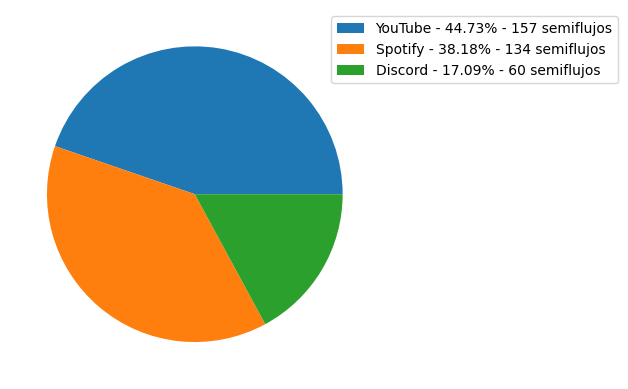

----------------------------------------------------------------------
----------------------------------------------------------------------

La clasificación ha sufrido un delay de 0.22 segundos
Esperando a que termine de generarse el archivo PCAP n°9 ...............

tshark: 
23868 packets captured


KeyboardInterrupt: 

In [11]:
## Bucle infinito de búsqueda de nuevos PCAP y procesamiento y clasificación de los semiflujos
## presentes en los mismos. El pie chart resultante representa el conjunto total de semiflujos capturados
## desde el comienzo de la grabación.

numPCAP = 1

dict_total_semiflujos_clasificados = {}

while True:
    ## Reiniciamos la condición del bucle while interno
    existe = False
      
    ## Necesitamos convertir el numero de PCAP, por ejemplo 3, a "00003"
    numConvertido = str(numPCAP+1).zfill(5)
    
    comando = "ls "+pathPCAPsComillas+"/PCAP_"+numConvertido+"* 2>/dev/null"   
    
    print("Esperando a que termine de generarse el archivo PCAP n°"+str(numPCAP)+" ...",end = "")
    ## Mientras no encontremos el PCAP que corresponde, no salimos del bucle
    while(existe == False):
        ## Espera de un segundo para no saturar con comprobaciones mientras no existe el archivo PCAP
        ## (Lo comprobamos una vez por segundo)
        time.sleep(1)
        
        stream = os.popen(comando)
        pathArchivoPCAPpendiente = stream.read()
        ## Ejecutamos el comando ls para comprobar si existe ya un nuevo PCAP que procesar(>.<)
        
        if(pathArchivoPCAPpendiente):
            existe = True
            start_time = time.time()
            ###############################
            ## Generamos el n° de PCAP que realmente queríamos
            numConvertido = str(numPCAP).zfill(5)
            comando = "ls "+pathPCAPsComillas+"/PCAP_"+numConvertido+"*"  
            stream = os.popen(comando)
            pathArchivoPCAPpendiente = stream.read()
            nombrePCAPprocesar = pathArchivoPCAPpendiente.replace(pathPCAPs, '')[1:-1] 
            ###########################          

            lista_semiflujos = PCAP_a_semiflujos(pathPCAPs,pathCSVs,nombrePCAPprocesar,normalizar,min_paquetes_flujo,\
                                                 token_separador,num_paquetes_semiflujo,tiempo_maximo_semiflujo,\
                                                 longitud_raw,num_hex_token)
            ## Clasificamos la lista de semiflujos, actualizando además el diccionario del total de semiflujos clasificados
            dict_total_semiflujos_clasificados = clasificar_semiflujos(model,lista_semiflujos,batch_size,clases_clasificador,dict_total_semiflujos_clasificados)           
            calcular_tiempo(start_time,clasificación_tiempo_real = True)
        else:
            ## Esperamos a que termine de generarse el PCAP correspondiente...
            print("...",end = "")
            
    ## Pasamos a buscar el siguiente PCAP
    numPCAP = numPCAP + 1

## ------------------------------------- 🎉 FIN DEL NOTEBOOK 🎉 -------------------------------------